# Results of the 9 experiment runs

The experiments ran on a free Google Colab T4 GPU through the Colab command-line tool, one run per command:

```
python run_experiment.py --name B_focal_g2 --loss focal --gamma 2 --seed 42
```

Each run saved its outputs, which are in this folder:

- `<run>/metrics.json`: the run's settings, its epoch-by-epoch training log, and its validation and test metrics
- `<run>/test_predictions.csv`: the predicted probability of pneumonia for each of the 585 test films
- `<run>/val_predictions.csv`: the same for the 585 validation films

`colab_logs/session1.ipynb` and `colab_logs/session2.ipynb` are the Colab tool's own timestamped record of the two GPU sessions: the code that was sent, what it printed, and every file that was downloaded.

This notebook reads the saved runs, shows each training log, and recomputes every number in the paper from the per-film scores. It does no training, so it runs on a laptop in a few seconds.

In [1]:
import csv, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

HERE = Path(".")
ROWS = {"A": "A_baseline", "B": "B_focal_g2", "C": "C_no_mask"}
LABELS = {"A": "Baseline (cross-entropy)", "B": "Focal loss, gamma = 2", "C": "Lung mask off"}
SEEDS = {42: "", 1: "_s1", 2: "_s2"}
RUNS = {f"{ROWS[r]}{s}": (r, seed) for r in ROWS for seed, s in SEEDS.items()}
runs = {name: json.loads((HERE / name / "metrics.json").read_text()) for name in RUNS}

print(f"{'run':16s} {'loss':6s} {'gamma':>5s} {'mask':>5s} {'seed':>4s} {'epochs':>6s} {'best':>4s} {'minutes':>7s}")
for name, m in runs.items():
    c = m["config"]
    best = max(m["history"], key=lambda h: h["val_accuracy"])["epoch"]
    print(f"{name:16s} {c['loss']:6s} {c['gamma']:5.1f} {str(c['lung_mask']):>5s} {c['seed']:4d} "
          f"{len(m['history']):6d} {best:4d} {m['minutes']:7.1f}")
print()
print("split used by every run:", runs["A_baseline"]["counts"])

run              loss   gamma  mask seed epochs best minutes
A_baseline       bce      2.0  True   42     15   10    21.9
A_baseline_s1    bce      2.0  True    1      7    2    18.0
A_baseline_s2    bce      2.0  True    2      8    3     3.1
B_focal_g2       focal    2.0  True   42      7    2     3.0
B_focal_g2_s1    focal    2.0  True    1      7    2     2.8
B_focal_g2_s2    focal    2.0  True    2     13    8     4.9
C_no_mask        bce      2.0 False   42     19   14     9.0
C_no_mask_s1     bce      2.0 False    1     16   11     5.9
C_no_mask_s2     bce      2.0 False    2     11    6     4.2

split used by every run: {'train': {'normal': 1267, 'pneumonia': 3419, 'total': 4686}, 'val': {'normal': 158, 'pneumonia': 427, 'total': 585}, 'test': {'normal': 158, 'pneumonia': 427, 'total': 585}}


## Training logs

One block per run: training loss, then validation accuracy, sensitivity (recall), and learning rate after each epoch. `*` marks the epoch whose weights were kept, the one with the best validation accuracy. Training stops after 5 epochs without improvement.

In [2]:
for name, m in runs.items():
    best = max(m["history"], key=lambda h: h["val_accuracy"])["epoch"]
    print(f"=== {name}")
    for h in m["history"]:
        mark = "*" if h["epoch"] == best else " "
        print(f" {mark} epoch {h['epoch']:2d}  loss {h['train_loss']:.4f}  val acc {h['val_accuracy']:6.2f}  "
              f"val sens {h['val_recall']:6.2f}  lr {h['lr']:.1e}")
    t = m["test"]
    print(f"   TEST  acc {t['accuracy']:.2f}  sens {t['recall']:.2f}  spec {t['specificity']:.2f}  "
          f"auc {t['auc']:.4f}  fp {t['fp']}  fn {t['fn']}")
    print()

=== A_baseline
   epoch  1  loss 0.8477  val acc  94.36  val sens  95.32  lr 1.0e-04
   epoch  2  loss 0.3359  val acc  95.56  val sens  98.59  lr 1.0e-04
   epoch  3  loss 0.2564  val acc  80.34  val sens  99.77  lr 1.0e-04
   epoch  4  loss 0.2029  val acc  83.25  val sens 100.00  lr 1.0e-04
   epoch  5  loss 0.1976  val acc  94.70  val sens  98.83  lr 3.0e-05
   epoch  6  loss 0.1739  val acc  96.24  val sens  96.25  lr 3.0e-05
   epoch  7  loss 0.1561  val acc  96.07  val sens  98.83  lr 3.0e-05
   epoch  8  loss 0.1452  val acc  93.85  val sens  99.30  lr 3.0e-05
   epoch  9  loss 0.1763  val acc  95.21  val sens  99.30  lr 9.0e-06
 * epoch 10  loss 0.1410  val acc  96.58  val sens  98.83  lr 9.0e-06
   epoch 11  loss 0.1348  val acc  96.41  val sens  98.83  lr 9.0e-06
   epoch 12  loss 0.1388  val acc  96.41  val sens  98.83  lr 9.0e-06
   epoch 13  loss 0.1447  val acc  95.38  val sens  99.06  lr 2.7e-06
   epoch 14  loss 0.1357  val acc  95.73  val sens  99.06  lr 2.7e-06
   ep

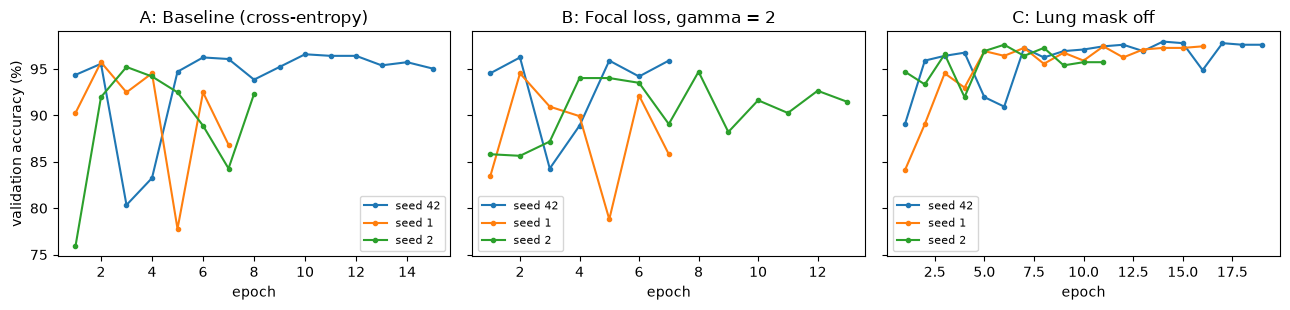

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, row in zip(axes, ROWS):
    for seed, suffix in SEEDS.items():
        h = runs[ROWS[row] + suffix]["history"]
        ax.plot([x["epoch"] for x in h], [x["val_accuracy"] for x in h], marker="o", ms=3, label=f"seed {seed}")
    ax.set_title(f"{row}: {LABELS[row]}")
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("validation accuracy (%)")
plt.tight_layout()
plt.show()

## Recompute the results table from the per-film scores

Row A′ needs no training. It reuses row A's scores and moves the decision threshold to the value that maximises sensitivity + specificity on the validation films. The check at the end compares the recomputed numbers with the ones each run saved.

In [4]:
def load(name, split):
    rows = list(csv.DictReader(open(HERE / name / f"{split}_predictions.csv")))
    return np.array([float(r["p_pneumonia"]) for r in rows]), np.array([int(r["label"]) for r in rows])

def scores(p, y, threshold=0.5):
    pred = p >= threshold
    tp = int(np.sum(pred & (y == 1))); tn = int(np.sum(~pred & (y == 0)))
    fp = int(np.sum(pred & (y == 0))); fn = int(np.sum(~pred & (y == 1)))
    return {"acc": 100 * (tp + tn) / len(y), "sens": 100 * tp / (tp + fn), "spec": 100 * tn / (tn + fp),
            "auc": roc_auc_score(y, p), "fp": fp, "fn": fn}

def val_threshold(name):
    p, y = load(name, "val")
    fpr, tpr, thr = roc_curve(y, p)
    return float(min(thr[int(np.argmax(tpr - fpr))], 1.0))

table = {"A": [], "A'": [], "B": [], "C": []}
for name, (row, seed) in RUNS.items():
    p, y = load(name, "test")
    table[row].append(scores(p, y))
    if row == "A":
        table["A'"].append(scores(p, y, val_threshold(name)))

print(f"{'row':3s} {'accuracy %':>14s} {'sensitivity %':>14s} {'specificity %':>14s} {'AUC':>15s} {'FP':>5s} {'FN':>5s}")
for row, results in table.items():
    col = lambda k, d: f"{np.mean([r[k] for r in results]):.{d}f} ± {np.std([r[k] for r in results], ddof=1):.{d}f}"
    print(f"{row:3s} {col('acc', 2):>14s} {col('sens', 2):>14s} {col('spec', 2):>14s} {col('auc', 4):>15s} "
          f"{np.mean([r['fp'] for r in results]):5.1f} {np.mean([r['fn'] for r in results]):5.1f}")

for name in RUNS:
    saved = runs[name]["test"]; again = scores(*load(name, "test"))
    assert abs(saved["accuracy"] - again["acc"]) < 1e-6 and abs(saved["auc"] - again["auc"]) < 1e-6, name
print()
print("check passed: the recomputed metrics match the metrics each run saved")

row     accuracy %  sensitivity %  specificity %             AUC    FP    FN
A     92.71 ± 0.55   95.32 ± 1.87   85.65 ± 3.25 0.9779 ± 0.0036  22.7  20.0
A'    92.42 ± 0.69   93.29 ± 1.51   90.08 ± 2.22 0.9779 ± 0.0036  15.7  28.7
B     91.68 ± 0.39   96.33 ± 1.08   79.11 ± 2.53 0.9746 ± 0.0027  33.0  15.7
C     95.78 ± 0.26   97.97 ± 0.36   89.87 ± 1.90 0.9934 ± 0.0010  16.0   8.7

check passed: the recomputed metrics match the metrics each run saved


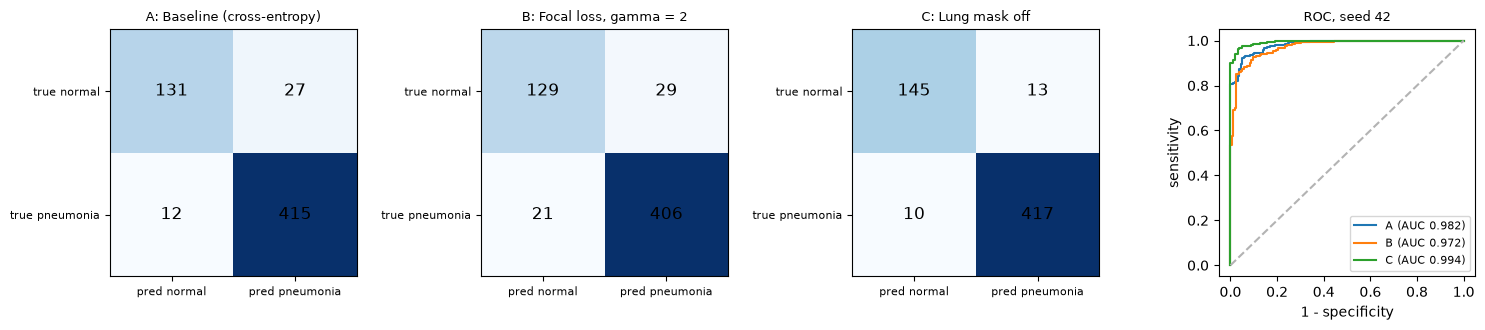

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for i, row in enumerate(ROWS):
    p, y = load(ROWS[row], "test")
    s = scores(p, y)
    matrix = np.array([[158 - s["fp"], s["fp"]], [s["fn"], 427 - s["fn"]]])
    axes[i].imshow(matrix, cmap="Blues")
    for a in range(2):
        for b in range(2):
            axes[i].text(b, a, matrix[a, b], ha="center", va="center", fontsize=12)
    axes[i].set_xticks([0, 1], ["pred normal", "pred pneumonia"], fontsize=8)
    axes[i].set_yticks([0, 1], ["true normal", "true pneumonia"], fontsize=8)
    axes[i].set_title(f"{row}: {LABELS[row]}", fontsize=9)
    fpr, tpr, _ = roc_curve(y, p)
    axes[3].plot(fpr, tpr, label=f"{row} (AUC {s['auc']:.3f})")
axes[3].plot([0, 1], [0, 1], "--", color="0.7")
axes[3].set_xlabel("1 - specificity"); axes[3].set_ylabel("sensitivity"); axes[3].legend(fontsize=8)
axes[3].set_title("ROC, seed 42", fontsize=9)
plt.tight_layout()
plt.show()

## Why focal loss lowered specificity

If focal loss had changed what the model learned, its AUC would differ and it would beat row A′. Instead, it only pulled the scores toward the middle.

In [6]:
for row in ROWS:
    extreme, med_normal, spec_tuned = [], [], []
    for seed, suffix in SEEDS.items():
        name = ROWS[row] + suffix
        p, y = load(name, "test")
        extreme.append(100 * np.mean((p < 0.1) | (p > 0.9)))
        med_normal.append(np.median(p[y == 0]))
        spec_tuned.append(scores(p, y, val_threshold(name))["spec"])
    print(f"{row}: films scored below 0.1 or above 0.9: {np.mean(extreme):4.1f}%   "
          f"median score of normal films: {np.mean(med_normal):.3f}   "
          f"specificity with tuned threshold: {np.mean(spec_tuned):.1f}%")

A: films scored below 0.1 or above 0.9: 77.8%   median score of normal films: 0.077   specificity with tuned threshold: 90.1%
B: films scored below 0.1 or above 0.9: 35.0%   median score of normal films: 0.345   specificity with tuned threshold: 90.1%


C: films scored below 0.1 or above 0.9: 94.4%   median score of normal films: 0.003   specificity with tuned threshold: 92.4%


## Failure analysis

**Lung-mask coverage.** For each test film, the share of the image the mask kept. Errors are row A, seed 42.

In [7]:
coverage = {r["file"]: float(r["mask_fraction"]) for r in csv.DictReader(open(HERE / "mask_coverage.csv"))}
rows = list(csv.DictReader(open(HERE / "A_baseline" / "test_predictions.csv")))
normal = [r for r in rows if r["label"] == "0"]
cut = sorted(coverage.values())[len(coverage) // 4]
wrong = lambda rs: sum(float(r["p_pneumonia"]) >= 0.5 for r in rs)
small = [r for r in normal if coverage[r["file"]] < cut]
rest = [r for r in normal if coverage[r["file"]] >= cut]
print(f"normal films in the smallest-mask quarter: {wrong(small)}/{len(small)} wrong = {100 * wrong(small) / len(small):.1f}%")
print(f"other normal films:                        {wrong(rest)}/{len(rest)} wrong = {100 * wrong(rest) / len(rest):.1f}%")

normal films in the smallest-mask quarter: 11/47 wrong = 23.4%
other normal films:                        16/111 wrong = 14.4%


**Recall by subtype.** The original file names mark each pneumonia film as bacterial or viral. The model was never trained on this split; we only count its errors. Mean over three seeds.

In [8]:
subtype = {r["file"]: r["subtype"] for r in csv.DictReader(open(HERE / "test_files.csv"))}
for row in ROWS:
    total, missed = {}, {}
    for suffix in SEEDS.values():
        for r in csv.DictReader(open(HERE / (ROWS[row] + suffix) / "test_predictions.csv")):
            k = subtype[r["file"]]
            total[k] = total.get(k, 0) + 1
            missed[k] = missed.get(k, 0) + ((float(r["p_pneumonia"]) >= 0.5) != (r["label"] == "1"))
    print(f"{row}: " + "   ".join(f"{k} {100 * (1 - missed[k] / total[k]):.1f}%" for k in ("normal", "bacterial", "viral")))

A: normal 85.7%   bacterial 96.5%   viral 93.4%
B: normal 79.1%   bacterial 97.1%   viral 95.0%
C: normal 89.9%   bacterial 98.6%   viral 96.9%


**Misclassified films with Grad-CAM** (seed 42, most confident errors first). Row A, with the lung mask:

![Row A failures](../report/figures/failures_A.png)

Row C, without the mask:

![Row C failures](../report/figures/failures_C.png)